# 4. Smooth monotone fits with I-splines

The monotone fit of Lecture 3 is a staircase, with zero slope on each step and no derivative at the jumps. A smooth monotone fit is obtained from I-splines, which are integrals of non-negative basis functions, with coefficients constrained to be non-negative. The lecture builds the basis, fits it by projected coordinate descent, and compares it with the staircase and with an unconstrained fit, including the cases where it does worse.

## Learning objectives

1. Construct the non-negative M-spline basis and the monotone I-spline basis (`linear_physics.ispline_basis_1d`).
2. Check that the derivative of each I-spline is the corresponding M-spline, by finite differences.
3. Fit smooth monotone curves by projected coordinate descent with non-negative coefficients (`linear_physics.fit_monotone_ispline`).
4. Build a convex Helmholtz energy from a monotone pressure curve.

**Time:** about 60 min

In [1]:
try:                      # use the installed package, or the copy in this repository
    import engml_2_applied
except ImportError:
    import pathlib, subprocess, sys
    for _root in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (_root / "engml_2_applied" / "__init__.py").exists():
            sys.path.insert(0, str(_root))
            break
    else:                 # on Google Colab: install from GitHub
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "git+https://github.com/ktwyw/engml-2-applied.git"], check=True)
    import engml_2_applied

import inspect
import numpy as np
import matplotlib.pyplot as plt
from engml_2_applied import (clustering_phases, constants, descriptors, dim_reduction, linear_physics,
                             trees_ensembles, uncertainty)
from engml_2_applied.plotting import panel_label, use_style

use_style()

def show_source(obj):
    """Return the source code of a library function or class."""
    return inspect.getsource(obj)

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## 1. Principles and governing equations
To obtain a smooth $C^\infty$ monotone surrogate $\hat{f}(x)$, **Ramsay's monotone spline framework (1988)** begins with $M$ non-negative localized bell-shaped **M-spline** basis functions $M_m(x) \ge 0$ centered at knots $\kappa_1 < \dots < \kappa_M$ with width $w$:
$$M_m(x) = \frac{1}{\sqrt{2\pi}\,w}\exp\!\left(-\frac{(x - \kappa_m)^2}{2w^2}\right) > 0, \qquad \int_{-\infty}^{\infty} M_m(u)\,du = 1 \tag{1.1}$$
Integrating each non-negative M-spline yields the monotonically increasing **I-spline** basis $I_m(x) \in (0, 1)$:
$$I_m(x) = \int_{-\infty}^{x} M_m(u)\,du = \frac{1}{2}\left[1 + \mathrm{erf}\!\left(\frac{x - \kappa_m}{\sqrt{2}\,w}\right)\right], \qquad \frac{dI_m(x)}{dx} = M_m(x) > 0 \tag{1.2}$$
Expanding our surrogate with a sign indicator $s \in \{+1, -1\}$ and **non-negative coefficients** $\beta_m \ge 0$ ($m=1,\dots,M$):
$$\hat{f}(x) = \beta_0 + s\sum_{m=1}^M \beta_m I_m(x), \qquad \beta_m \ge 0 \implies s\,\hat{f}'(x) = \sum_{m=1}^M \beta_m M_m(x) \ge 0 \quad \forall x \in \mathbb{R} \tag{1.3}$$
We solve $\min_{\beta_0 \in \mathbb{R},\,\boldsymbol{\beta}_{1:M} \ge \mathbf{0}} \frac{1}{2}\|\boldsymbol{\Phi}\boldsymbol{\beta} - \mathbf{y}\|_2^2 + \frac{\lambda N}{2}\|\boldsymbol{\beta}_{1:M}\|_2^2$ via projected coordinate descent onto the non-negative orthant $\beta_m \leftarrow \max(0, \tilde{\beta}_m)$.

In [2]:
heading("Demonstration 1: Non-Negative M-Spline & Cumulative I-Spline Basis Verification")
x_grid = np.linspace(0.0, 10.0, 101)
knots = np.linspace(0.0, 10.0, 8)
I_mat, M_mat = linear_physics.ispline_basis_1d(x_grid, knots)

eps = 1e-5
I_plus, _ = linear_physics.ispline_basis_1d(x_grid + eps, knots)
I_minus, _ = linear_physics.ispline_basis_1d(x_grid - eps, knots)
dI_fd = (I_plus - I_minus) / (2.0 * eps)

print(f"Basis matrix shapes: I_mat = {I_mat.shape}, M_mat = {M_mat.shape}")
print(f"M-spline range     : [{np.min(M_mat):.4e}, {np.max(M_mat):.4f}] (Strictly non-negative)")
print(f"I-spline range     : [{np.min(I_mat):.4f}, {np.max(I_mat):.4f}] (Strictly bounded in [0, 1])")
print(f"Max derivative check ||dI/dx - M||_max: {np.max(np.abs(dI_fd - M_mat)):.2e}")
assert np.all(M_mat >= 0.0) and np.all((I_mat >= 0.0) & (I_mat <= 1.0))
assert np.allclose(dI_fd, M_mat, atol=1e-7)


Demonstration 1: Non-Negative M-Spline & Cumulative I-Spline Basis Verification
Basis matrix shapes: I_mat = (101, 8), M_mat = (101, 8)
M-spline range     : [4.5187e-20, 0.3723] (Strictly non-negative)
I-spline range     : [0.0000, 1.0000] (Strictly bounded in [0, 1])
Max derivative check ||dI/dx - M||_max: 2.25e-11


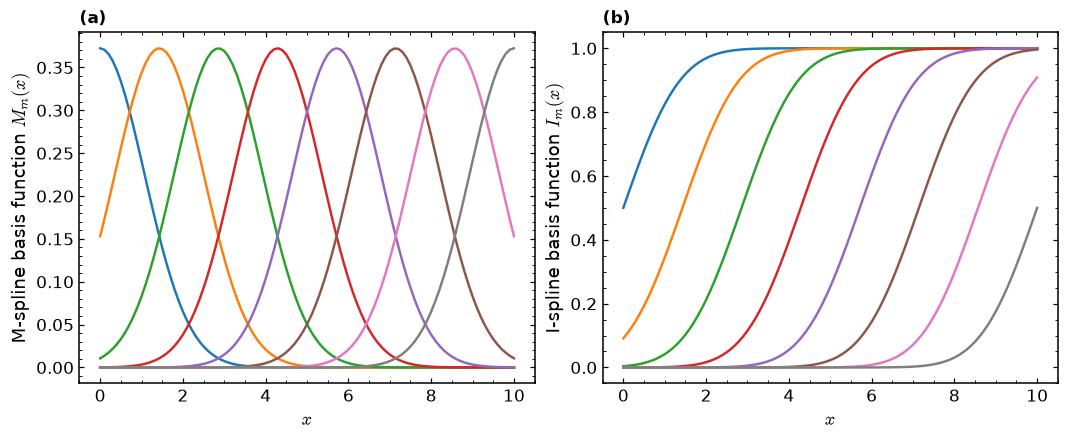

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
for m in range(M_mat.shape[1]):
    ax1.plot(x_grid, M_mat[:, m]); ax2.plot(x_grid, I_mat[:, m])
ax1.set_xlabel("$x$"); ax1.set_ylabel("M-spline basis function $M_m(x)$"); ax1.set_title("(a)", loc="left", fontweight="bold")
ax2.set_xlabel("$x$"); ax2.set_ylabel("I-spline basis function $I_m(x)$"); ax2.set_title("(b)", loc="left", fontweight="bold")
plt.show()

**Figure 4.1.** The two bases of this lecture, for eight knots. (a) The M-splines: non-negative bumps. (b) The I-splines, their integrals: each rises from 0 to 1 and never falls, so a sum of them with non-negative weights cannot fall either.

**What Demonstration 1 shows.** Every column of $\mathbf{M}$ is non-negative and is the derivative of the corresponding column of $\mathbf{I}$ (to $2\times 10^{-11}$ by finite differences). A combination of I-splines with non-negative coefficients therefore has a non-negative, continuous derivative everywhere.

---

## 2. Numerical walkthrough
Let us fit a smooth monotone increasing I-spline surrogate to $N = 50$ noisy synthetic $\mathrm{CO_2}$ adsorption uptake points $q(P)$ and inspect the non-negative coefficient vector $\hat{\boldsymbol{\beta}}_{1:M} \ge \mathbf{0}$ found by projected coordinate descent.

In [4]:
heading("Demonstration 2: Projected Coordinate Descent & Non-Negative Coefficient Spectrum")
rng = np.random.default_rng(42)
P_bar = np.linspace(0.1, 10.0, 50)
q_true = 5.2 * 1.4 * P_bar / (1.0 + 1.4 * P_bar)
q_obs = q_true + rng.normal(0.0, 0.18, size=50)

knots_ads = np.linspace(0.1, 10.0, 9)
isp_fit = linear_physics.fit_monotone_ispline(P_bar, q_obs, knots=knots_ads, increasing=True)
print("Intercept beta_0 :", round(float(isp_fit["beta"][0]), 4))
print("Non-negative I-spline weights beta_{1..9}:", np.round(isp_fit["beta"][1:], 4))
print(f"Min analytical slope dq/dP across [0.1, 10] bar: {np.min(isp_fit['dy_dx']):.4e} >= 0")
assert np.all(isp_fit["beta"][1:] >= 0.0) and np.all(isp_fit["dy_dx"] >= -1e-15)


Demonstration 2: Projected Coordinate Descent & Non-Negative Coefficient Spectrum
Intercept beta_0 : -1.1439
Non-negative I-spline weights beta_{1..9}: [4.3165 1.0605 0.     0.2264 0.2839 0.     0.     0.2003 0.    ]
Min analytical slope dq/dP across [0.1, 10] bar: 2.8000e-02 >= 0


**What Demonstration 2 shows.** Projected coordinate descent leaves four of the nine weights exactly at zero, on the boundary of the constraint, and the fitted isotherm has a slope $dq/dP$ of at least $0.028$ over the whole range from $0.1$ to $10\;\mathrm{bar}$.

---

## 3. Worked case study
Let us benchmark our smooth monotone I-spline against staircase PAVA and an unconstrained degree-8 polynomial on both **value accuracy** ($\mathrm{RMSE}(q)$) and **derivative accuracy** ($\mathrm{RMSE}(dq/dP)$).

In [5]:
heading("Demonstration 3: Value & Derivative Benchmark — I-Spline vs. PAVA vs. Polynomial")
dq_dP_true = 5.2 * 1.4 / ((1.0 + 1.4 * P_bar) ** 2)
q_pava_ads = linear_physics.pava_monotone_regression(q_obs, increasing=True)
dq_dP_pava = np.gradient(q_pava_ads, P_bar)

poly8 = np.polyfit(P_bar, q_obs, deg=8)
q_poly8 = np.polyval(poly8, P_bar)
dq_dP_poly8 = np.polyval(np.polyder(poly8), P_bar)

for name, q_m, dq_m in [("Unconstrained Poly-8", q_poly8, dq_dP_poly8), ("Staircase PAVA", q_pava_ads, dq_dP_pava), ("Smooth I-Spline", isp_fit["y_pred"], isp_fit["dy_dx"])]:
    v_rmse = float(np.sqrt(np.mean((q_m - q_true) ** 2)))
    d_rmse = float(np.sqrt(np.mean((dq_m - dq_dP_true) ** 2)))
    n_viol = int(np.sum(dq_m < -1e-12))
    print(f"{name:22s} | Value RMSE = {v_rmse:.4f} | Slope RMSE = {d_rmse:.4f} | Slope Violations = {n_viol}")
assert np.sqrt(np.mean((isp_fit["y_pred"] - q_true) ** 2)) < 0.12
assert int(np.sum(isp_fit["dy_dx"] < -1e-12)) == 0 and int(np.sum(dq_dP_poly8 < -1e-12)) > 0


Demonstration 3: Value & Derivative Benchmark — I-Spline vs. PAVA vs. Polynomial
Unconstrained Poly-8   | Value RMSE = 0.0472 | Slope RMSE = 0.2296 | Slope Violations = 5
Staircase PAVA         | Value RMSE = 0.0828 | Slope RMSE = 0.4342 | Slope Violations = 0
Smooth I-Spline        | Value RMSE = 0.0995 | Slope RMSE = 0.5624 | Slope Violations = 0


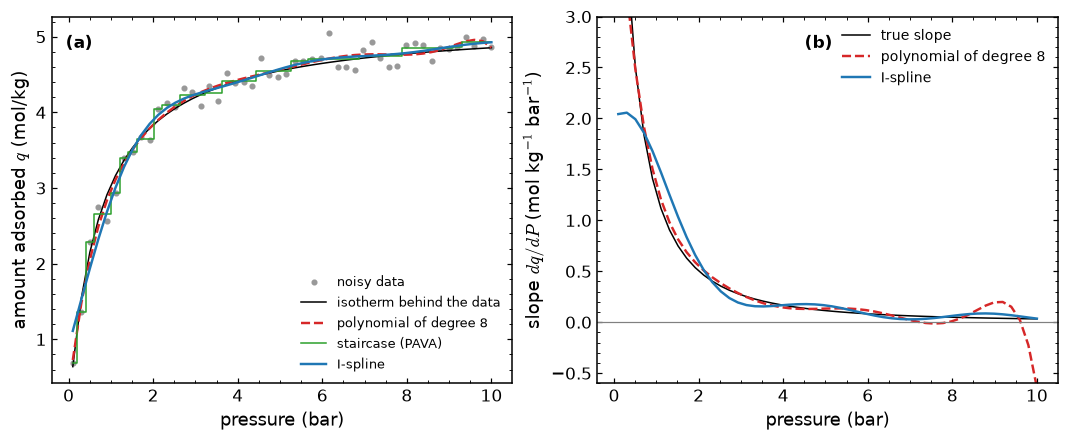

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
ax1.plot(P_bar, q_obs, "o", ms=3, color="0.6", label="noisy data")
ax1.plot(P_bar, q_true, "-", color="k", lw=1.0, label="isotherm behind the data")
ax1.plot(P_bar, q_poly8, "--", color="C3", label="polynomial of degree 8")
ax1.step(P_bar, q_pava_ads, where="mid", color="C2", lw=1.0, label="staircase (PAVA)")
ax1.plot(P_bar, isp_fit["y_pred"], "-", color="C0", label="I-spline")
ax1.set_xlabel("pressure (bar)"); ax1.set_ylabel("amount adsorbed $q$ (mol/kg)"); ax1.legend(fontsize=8.5, loc="lower right"); panel_label(ax1, "(a)")
ax2.plot(P_bar, dq_dP_true, "-", color="k", lw=1.0, label="true slope")
ax2.plot(P_bar, dq_dP_poly8, "--", color="C3", label="polynomial of degree 8")
ax2.plot(P_bar, isp_fit["dy_dx"], "-", color="C0", label="I-spline")
ax2.axhline(0.0, color="0.5", lw=0.8); ax2.set_ylim(-0.6, 3.0)
ax2.set_xlabel("pressure (bar)"); ax2.set_ylabel("slope $dq/dP$ (mol kg$^{-1}$ bar$^{-1}$)"); ax2.legend(fontsize=9); panel_label(ax2, "(b)", x=0.45)
plt.show()

**Figure 4.2.** Three fits to a synthetic adsorption isotherm. (a) The fitted curves. (b) Their slopes (the slope of the staircase is zero or undefined and is not drawn). The polynomial follows the true slope most closely but its slope becomes negative near the upper end; the slope of the I-spline is never negative, and with nine knots it is too coarse to follow the steep rise at low pressure.

**What Demonstration 3 shows.** The comparison does not favour the constrained fits on accuracy. The unconstrained polynomial of degree 8 has the smallest error in the value ($0.047$) and in the slope ($0.23$), but its slope has the wrong sign in 5 places. The monotone fits have no violation and larger errors: $0.083$ and $0.43$ for the staircase, $0.100$ and $0.56$ for the I-spline with this set of knots. What the I-spline offers over the staircase is a continuous derivative, which a process simulator needs; what it costs here is resolution, and Demonstration 4 shows that more knots recover it.

---

## 4. What if: sensitivity to the parameters
How does the number of knots $M \in \{4, 8, 14, 22\}$ affect the smooth I-spline fit, and how does integrating a decreasing pressure I-spline $\hat{P}(V_m)$ produce a guaranteed **convex Helmholtz free-energy potential** $\hat{A}_m(V_m)$ with $\partial^2 \hat{A}_m / \partial V_m^2 = -\partial \hat{P}/\partial V_m \ge 0$?

In [7]:
heading("Demonstration 4: Knot Density Sweep & Convex Helmholtz Free-Energy Curvature")
for n_k in [4, 8, 14, 22]:
    fit_k = linear_physics.fit_monotone_ispline(P_bar, q_obs, knots=np.linspace(0.1, 10.0, n_k), increasing=True)
    v_err = float(np.sqrt(np.mean((fit_k["y_pred"] - q_true) ** 2)))
    print(f"Knots M = {n_k:2d} | Active positive weights = {int(np.sum(fit_k['beta'][1:] > 1e-5)):2d} | Value RMSE = {v_err:.4f} | Min slope = {np.min(fit_k['dy_dx']):.2e}")

Vm = np.linspace(0.15, 0.80, 45)
P_iso_noisy = 25.0 / Vm + rng.normal(0.0, 1.5, size=45)
isp_p = linear_physics.fit_monotone_ispline(Vm, P_iso_noisy, knots=np.linspace(0.15, 0.80, 8), increasing=False)
d2A_dVm2 = -isp_p["dy_dx"]
print(f"\nMin Helmholtz free-energy curvature d^2 A_m / dV_m^2 = {np.min(d2A_dVm2):.4e} >= 0 (Strictly convex)")
assert np.all(d2A_dVm2 >= -1e-15)


Demonstration 4: Knot Density Sweep & Convex Helmholtz Free-Energy Curvature
Knots M =  4 | Active positive weights =  1 | Value RMSE = 0.2476 | Min slope = 3.29e-04
Knots M =  8 | Active positive weights =  6 | Value RMSE = 0.1035 | Min slope = 4.13e-02
Knots M = 14 | Active positive weights = 10 | Value RMSE = 0.0731 | Min slope = 1.20e-02
Knots M = 22 | Active positive weights = 12 | Value RMSE = 0.0610 | Min slope = 4.69e-04

Min Helmholtz free-energy curvature d^2 A_m / dV_m^2 = 5.0595e+01 >= 0 (Strictly convex)


**What Demonstration 4 shows.** With more knots the error falls, from $0.25$ with 4 knots to $0.061$ with 22, and the slope stays non-negative in every case: the constraint $\beta_m \ge 0$ prevents the oscillations that an unconstrained fit of the same flexibility would show. The second derivative of the Helmholtz energy of the last example is positive everywhere.

---

## Inside the algorithm
Below we run a standalone projected coordinate descent loop on the non-negative orthant in pure NumPy and verify digit-for-digit agreement with `linear_physics.fit_monotone_ispline`.

In [8]:
heading("Inside the Algorithm: By-Hand Projected Coordinate Descent vs. the Library")
I_b, M_b = linear_physics.ispline_basis_1d(P_bar, knots_ads)
Phi = np.column_stack([np.ones_like(P_bar), I_b])
n_s, p_s = Phi.shape
beta_hand = np.zeros(p_s)
beta_hand[0] = float(np.mean(q_obs))
col_sq = np.sum(Phi ** 2, axis=0) + np.concatenate([[0.0], np.full(p_s - 1, 1e-6 * n_s)])
res_vec = q_obs - Phi @ beta_hand
for _ in range(800):
    b_prev = beta_hand.copy()
    for j in range(p_s):
        old_v = beta_hand[j]
        rho = float(np.dot(Phi[:, j], res_vec)) + float(np.sum(Phi[:, j] ** 2)) * old_v
        new_v = (rho / col_sq[j]) if j == 0 else max(0.0, rho / col_sq[j])
        if new_v != old_v:
            res_vec -= Phi[:, j] * (new_v - old_v)
            beta_hand[j] = new_v
    if np.max(np.abs(beta_hand - b_prev)) < 1e-10:
        break
diff_isp = float(np.max(np.abs(beta_hand - isp_fit["beta"])))
print("by hand (pure NumPy) beta[:5]:", np.round(beta_hand[:5], 6))
print("library (engml_2_applied)      beta[:5]:", np.round(isp_fit["beta"][:5], 6))
print(f"Max digit-for-digit discrepancy: {diff_isp:.2e}")
assert diff_isp < 1e-13


Inside the Algorithm: By-Hand Projected Coordinate Descent vs. the Library
by hand (pure NumPy) beta[:5]: [-1.143884  4.316474  1.060545  0.        0.226421]
library (engml_2_applied)      beta[:5]: [-1.143884  4.316474  1.060545  0.        0.226421]
Max digit-for-digit discrepancy: 0.00e+00


## Exercises

1. **Verify a result.** Fit a decreasing smooth monotone I-spline (`increasing=False`) to noisy shear-thinning polymer viscosity measurements $\log_{10}\eta(\dot{\gamma})$ across $\log_{10}\dot{\gamma} \in [-1, 3]$ generated from a Carreau–Yasuda fluid $\eta(\dot{\gamma}) = \eta_0 (1 + (\lambda\dot{\gamma})^2)^{(n-1)/2}$ ($\eta_0 = 1000\;\mathrm{Pa\cdot s}, \lambda = 1.0\;\mathrm{s}, n = 0.35$) with noise $\sigma = 0.08$. Verify that the fitted slope $d(\log_{10}\hat{\eta})/d(\log_{10}\dot{\gamma}) \le 0$ at every point and that the test RMSE against the true viscosity curve is below $0.05$.
2. **Find how it fails.** Compare Newton–Raphson inversion $\hat{q}(P^*) = q_{\mathrm{target}} = 3.0\;\mathrm{mol/kg}$ on the smooth I-spline surrogate (`isp_fit`) versus the staircase PAVA curve. Show that Newton–Raphson on the smooth I-spline converges to $|\hat{q}(P^*) - 3.0| < 10^{-12}$ in $\le 6$ iterations.
3. **Write it yourself.** Implement a **C-spline** (convex spline) basis generator `convex_cspline_basis_1d(x, knots)` by integrating the monotone I-spline basis $C_m(x) = \int_{x_0}^x I_m(u)\,du$ via cumulative trapezoidal quadrature so that $C_m''(x) = M_m(x) \ge 0$, and verify that any non-negative combination $\hat{A}(x) = \sum_{m=1}^M \beta_m C_m(x)$ ($\beta_m > 0$) has strictly positive second derivative $\hat{A}''(x) > 0$ everywhere.

The cell below works Exercise 1 as a first check; all three are solved in the solutions notebook of this lecture.

In [9]:
heading("Exercise 1: Carreau-Yasuda Shear-Thinning Polymer Viscosity I-Spline")
rng_rheo = np.random.default_rng(19)
log_gdot = np.linspace(-1.0, 3.0, 45)
gdot = 10.0 ** log_gdot
log_eta_true = np.log10(1000.0 * ((1.0 + gdot ** 2) ** ((0.35 - 1.0) / 2.0)))
log_eta_noisy = log_eta_true + rng_rheo.normal(0.0, 0.08, size=45)

rheo_isp = linear_physics.fit_monotone_ispline(log_gdot, log_eta_noisy, knots=np.linspace(-1.0, 3.0, 8), increasing=False)
rmse_rheo = float(np.sqrt(np.mean((rheo_isp["y_pred"] - log_eta_true) ** 2)))
print(f"Shear-thinning I-spline RMSE = {rmse_rheo:.4f} | Max slope = {np.max(rheo_isp['dy_dx']):.4e} <= 0")
assert np.all(rheo_isp["dy_dx"] <= 1e-15) and rmse_rheo < 0.05


Exercise 1: Carreau-Yasuda Shear-Thinning Polymer Viscosity I-Spline
Shear-thinning I-spline RMSE = 0.0300 | Max slope = -2.7180e-02 <= 0
